<a href="https://colab.research.google.com/github/Mrudhulraj/llm-caching/blob/main/stage3_grpo_clip03_controlled_ttft.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GRPO clip 0.3 — controlled base vs LoRA vs merged-LoRA TTFT

**Goal:** train one Qwen2.5-0.5B-Instruct LoRA adapter with the best observed clipping configuration (**K1, 3 inner epochs, epsilon=0.3**), evaluate accuracy, then compare local first-token inference latency on the **same warmed GPU**.

Compare **base**, **unmerged LoRA**, and **merged LoRA**. Timings alternate between models in randomized blocks, with fixed tokenized inputs, warm-up, CUDA synchronization, and prompt-length reporting. This is a local `generate(max_new_tokens=1)` latency proxy, **not HTTP/server TTFT**. Results are not pre-filled; run in Colab with GPU. This notebook deliberately trains only one configuration rather than all eight.


In [1]:
%pip -q install "transformers>=4.46,<5" "peft>=0.13,<1" "accelerate>=1.0,<2" "huggingface_hub>=0.26" pandas matplotlib tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 72.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 81.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os, gc, random, re, time, json
from contextlib import nullcontext
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model
from huggingface_hub import snapshot_download

assert torch.cuda.is_available(), "GPU required: Runtime > Change runtime type > T4 GPU"
DEVICE = torch.device("cuda")
DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
MODEL_DIR = "/content/models/Qwen2.5-0.5B-Instruct"
OUTPUT_DIR = Path("/content/grpo_stage3_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
print("GPU:", torch.cuda.get_device_name(0), "| dtype:", DTYPE, "| free/total GiB:", [round(x/2**30,2) for x in torch.cuda.mem_get_info()])

GPU: Tesla T4 | dtype: torch.bfloat16 | free/total GiB: [14.46, 14.56]


In [3]:
# Downloads the public model into Colab's local disk; subsequent runs reuse cached files.
MODEL_PATH = snapshot_download(repo_id=MODEL_ID, local_dir=MODEL_DIR)
print("Model available at:", MODEL_PATH)
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH, padding_side="left")
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
print("EOS token:", tokenizer.eos_token_id, "| pad token:", tokenizer.pad_token_id)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

merges.txt: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

Model available at: /content/models/Qwen2.5-0.5B-Instruct
EOS token: 151645 | pad token: 151643


In [4]:
def generate_addition_dataset(n=200, seed=42):
    rng = random.Random(seed)
    return [(f"What is {a}+{b}? Answer with just the number.", str(a+b))
            for a,b in ((rng.randint(100,999), rng.randint(100,999)) for _ in range(n))]

def compute_reward_addition(texts, answers):
    # Preserve the source's last-number reward rule.
    return [float(bool((nums := re.findall(r"\d+", text)) and nums[-1] == ans))
            for text,ans in zip(texts,answers)]

TRAIN_DATA = generate_addition_dataset(n=200, seed=42)
EVAL_DATA = generate_addition_dataset(n=200, seed=2026)
# Ensure no prompt overlaps across train/evaluation sets.
train_prompts = {p for p, _ in TRAIN_DATA}
EVAL_DATA = [(p,a) for p,a in EVAL_DATA if p not in train_prompts]
DATA = TRAIN_DATA
print("Train examples:",len(TRAIN_DATA),"Held-out examples:",len(EVAL_DATA))
print("Training examples:",TRAIN_DATA[:2])
print("Held-out examples:",EVAL_DATA[:2])

Train examples: 200 Held-out examples: 200
Training examples: [('What is 754+214? Answer with just the number.', '968'), ('What is 125+859? Answer with just the number.', '984')]
Held-out examples: [('What is 221+427? Answer with just the number.', '648'), ('What is 614+624? Answer with just the number.', '1238')]


In [5]:
# First run with QUICK_TEST=True to verify every experiment. Then set False for the source's 30 steps each.
QUICK_TEST = False
NUM_STEPS = 2 if QUICK_TEST else 30
GROUP_SIZE = 4
MAX_NEW_TOKENS = 16
LEARNING_RATE = 5e-5  # LoRA parameters; original full-model script used 5e-6
BETA = 0.1
LOG_EVERY = 1 if QUICK_TEST else 5
EVAL_SAMPLES = 12 if QUICK_TEST else 100  # Same held-out prompts for every run
EVAL_BATCH_SIZE = 4  # Lower to 2 if T4 runs out of memory
EVAL_MAX_NEW_TOKENS = 16
SAVE_ADAPTERS = True
print("Training steps per experiment:", NUM_STEPS, "| experiments: 8")
print("Held-out evaluation questions:", EVAL_SAMPLES)
CLIP_EPSILON = 0.3
INNER_EPOCHS = 3
KL_MODE = "K1"


Training steps per experiment: 30 | experiments: 8
Held-out evaluation questions: 100


In [6]:
def selected_log_probs(model, ids, attention_mask):
    out = model(input_ids=ids, attention_mask=attention_mask, use_cache=False)
    logits = out.logits[:, :-1, :].float()
    targets = ids[:, 1:]
    return F.log_softmax(logits, dim=-1).gather(-1, targets.unsqueeze(-1)).squeeze(-1)

def completion_mask(ids, prompt_len, eos_id):
    # Include generated EOS itself, but exclude tokens following EOS (including padding).
    comp = ids[:, prompt_len:]
    eos = comp.eq(eos_id)
    valid = (eos.cumsum(dim=1) - eos.long()).eq(0)
    mask = torch.zeros((ids.size(0), ids.size(1)-1), device=ids.device, dtype=torch.float32)
    mask[:, prompt_len-1:] = valid.float()
    return mask

def load_policy():
    base = AutoModelForCausalLM.from_pretrained(MODEL_PATH, torch_dtype=DTYPE, low_cpu_mem_usage=True).to(DEVICE)
    base.config.use_cache = False
    config = LoraConfig(r=8, lora_alpha=16, lora_dropout=0.0,
                        target_modules=["q_proj","v_proj"], bias="none", task_type="CAUSAL_LM")
    model = get_peft_model(base, config)
    model.gradient_checkpointing_enable()
    model.enable_input_require_grads()
    return model

def evaluate_addition(model, experiment, split, samples=None):
    """Greedy, deterministic evaluation with no optimizer updates."""
    examples = EVAL_DATA[:EVAL_SAMPLES] if samples is None else samples
    model.eval()
    rows = []
    for offset in range(0, len(examples), EVAL_BATCH_SIZE):
        batch = examples[offset:offset+EVAL_BATCH_SIZE]
        formatted = [tokenizer.apply_chat_template(
            [{"role":"user", "content":prompt}], tokenize=False,
            add_generation_prompt=True) for prompt, _ in batch]
        inputs = tokenizer(formatted, return_tensors="pt", padding=True).to(DEVICE)
        prompt_width = inputs.input_ids.shape[1]
        with torch.inference_mode():
            outputs = model.generate(**inputs, do_sample=False,
                max_new_tokens=EVAL_MAX_NEW_TOKENS,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id, use_cache=True)
        predictions = tokenizer.batch_decode(outputs[:,prompt_width:], skip_special_tokens=True)
        rewards = compute_reward_addition(predictions,[ans for _,ans in batch])
        for (prompt, answer), prediction, reward in zip(batch, predictions, rewards):
            rows.append({"experiment":experiment,"split":split,"prompt":prompt,
                         "expected":answer,"generated":prediction,
                         "correct":int(reward),
                         "format_ok":int(bool(re.fullmatch(r"\s*\d+\s*", prediction)))})
    return rows

# Evaluate the original pretrained model once, without a LoRA adapter.
# This is the SAME held-out set and decoding procedure used after every run.
def evaluate_base_model():
    print("Evaluating pretrained base model before GRPO...",flush=True)
    base = AutoModelForCausalLM.from_pretrained(
        MODEL_PATH, torch_dtype=DTYPE, low_cpu_mem_usage=True).to(DEVICE)
    try:
        rows = evaluate_addition(base,"base","before")
        ttft_rows = []
    finally:
        del base
        gc.collect(); torch.cuda.empty_cache()
    return rows, ttft_rows

def run_grpo_experiment(name, group_size=GROUP_SIZE, learning_rate=LEARNING_RATE,
                        beta=BETA, clip_epsilon=0.2, inner_update_epochs=3,
                        num_steps=NUM_STEPS, max_new_tokens=MAX_NEW_TOKENS,
                        kl_mode="K1", log_every=LOG_EVERY):
    assert kl_mode in ("K1", "K3")
    print(f"\n=== {name}: KL={kl_mode}, epochs={inner_update_epochs}, clip={clip_epsilon} ===", flush=True)
    torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    model = load_policy()
    optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad), lr=learning_rate)
    metrics = {k: [] for k in ["loss", "reward", "kl", "raw_reward", "grad_norm"]}
    evaluation_rows = []
    ttft_rows = []
    try:
        for step in range(num_steps):
            prompt, answer = DATA[step % len(DATA)]
            formatted = tokenizer.apply_chat_template([{"role":"user", "content":prompt}],
                                                      tokenize=False, add_generation_prompt=True)
            inputs = tokenizer(formatted, return_tensors="pt").to(DEVICE)
            prompt_len = inputs.input_ids.shape[1]
            model.eval()
            with torch.no_grad():
                generated = model.generate(input_ids=inputs.input_ids.repeat(group_size,1),
                                           attention_mask=inputs.attention_mask.repeat(group_size,1),
                                           max_new_tokens=max_new_tokens, do_sample=True,
                                           temperature=0.8, top_p=1.0,
                                           pad_token_id=tokenizer.pad_token_id,
                                           eos_token_id=tokenizer.eos_token_id,
                                           use_cache=True)
                comp = generated[:, prompt_len:]
                completions = tokenizer.batch_decode(comp, skip_special_tokens=True)
                rewards = torch.tensor(compute_reward_addition(completions,[answer]*group_size),device=DEVICE)
                mask = completion_mask(generated, prompt_len, tokenizer.eos_token_id)
                # Attention is valid through EOS; pad==eos means token ID alone cannot determine padding.
                attn = torch.cat([torch.ones((group_size,prompt_len),device=DEVICE,dtype=torch.long),
                                  mask[:,prompt_len-1:].long()], dim=1)
                old_lp = selected_log_probs(model, generated, attn).detach()
                with model.disable_adapter():
                    ref_lp = selected_log_probs(model, generated, attn).detach()
                sampled_kl = ((old_lp-ref_lp)*mask).sum(dim=1)
                if kl_mode == "K1":
                    adjusted = rewards - beta * sampled_kl
                else:
                    adjusted = rewards
                advantages = (adjusted-adjusted.mean()) / (adjusted.std(unbiased=False)+1e-4)
            model.train()
            losses=[]; norms=[]
            for epoch in range(inner_update_epochs):
                lp = selected_log_probs(model, generated, attn)
                ratio = (lp-old_lp).clamp(-20,20).exp()
                adv = advantages[:,None]
                surr = torch.minimum(ratio*adv, ratio.clamp(1-clip_epsilon,1+clip_epsilon)*adv)
                loss = -(surr*mask).sum() / mask.sum().clamp_min(1)
                if kl_mode == "K3":
                    # Nonnegative Schulman k3 estimator: exp(ref_logp - policy_logp) - (ref_logp - policy_logp) - 1.
                    # Critically: DO NOT detach lp; KL must backpropagate into policy.
                    log_r = (ref_lp-lp).clamp(-20,20)
                    k3 = log_r.exp() - log_r - 1
                    loss = loss + beta*(k3*mask).sum()/mask.sum().clamp_min(1)
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
                optimizer.step()
                losses.append(float(loss.detach())); norms.append(float(norm))
            metrics["loss"].append(float(np.mean(losses)))
            metrics["reward"].append(float(rewards.mean()))
            metrics["raw_reward"].append(float(rewards.mean()))
            metrics["kl"].append(float(sampled_kl.mean()))  # sampled log-ratio, not exact KL
            metrics["grad_norm"].append(float(np.mean(norms)))
            if step % log_every == 0 or step == num_steps-1:
                print(f"Step {step+1:3}/{num_steps} | loss={metrics['loss'][-1]:.4f} | "
                      f"reward={metrics['reward'][-1]:.3f} | sampledKL={metrics['kl'][-1]:.4f} | "
                      f"grad={metrics['grad_norm'][-1]:.3f}", flush=True)
        # Evaluate the trained LoRA policy BEFORE freeing model memory.
        evaluation_rows = evaluate_addition(model, name, "after")
        accuracy = np.mean([r["correct"] for r in evaluation_rows])
        format_rate = np.mean([r["format_ok"] for r in evaluation_rows])
        print(f"HELD-OUT AFTER | {name} | accuracy={accuracy:.1%} | format={format_rate:.1%}", flush=True)
        ttft_rows = []
        if SAVE_ADAPTERS:
            safe_name = re.sub(r"[^A-Za-z0-9_-]+", "_", name)
            model.save_pretrained(str(OUTPUT_DIR / "adapters" / safe_name))
    finally:
        del optimizer, model
        gc.collect(); torch.cuda.empty_cache()
    return metrics, evaluation_rows, ttft_rows


## Train one configuration and measure accuracy before/after

In [8]:
! pip install torchao==0.16.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 59.3 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [9]:
BASE_EVAL_ROWS, _ = evaluate_base_model()
BASE_ACCURACY = float(np.mean([r['correct'] for r in BASE_EVAL_ROWS]))
print(f'Base accuracy: {BASE_ACCURACY:.1%}')
metrics, AFTER_EVAL_ROWS, _ = run_grpo_experiment(
    'K1_clip_0.3', kl_mode=KL_MODE, clip_epsilon=CLIP_EPSILON,
    inner_update_epochs=INNER_EPOCHS
)
AFTER_ACCURACY = float(np.mean([r['correct'] for r in AFTER_EVAL_ROWS]))
print(f'After accuracy: {AFTER_ACCURACY:.1%}; delta: {(AFTER_ACCURACY-BASE_ACCURACY)*100:+.1f} percentage points')
pd.DataFrame(BASE_EVAL_ROWS + AFTER_EVAL_ROWS).to_csv(OUTPUT_DIR/'accuracy_predictions.csv',index=False)


Evaluating pretrained base model before GRPO...
Base accuracy: 70.0%

=== K1_clip_0.3: KL=K1, epochs=3, clip=0.3 ===
Step   1/30 | loss=0.0000 | reward=0.000 | sampledKL=0.0000 | grad=0.000
Step   6/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0012 | grad=0.000
Step  11/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0004 | grad=0.000
Step  16/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0010 | grad=0.000
Step  21/30 | loss=-0.0273 | reward=0.250 | sampledKL=0.6906 | grad=7.426
Step  26/30 | loss=0.0000 | reward=1.000 | sampledKL=0.5309 | grad=0.000
Step  30/30 | loss=0.0000 | reward=1.000 | sampledKL=-0.0143 | grad=0.000
HELD-OUT AFTER | K1_clip_0.3 | accuracy=83.0% | format=100.0%
After accuracy: 83.0%; delta: +13.0 percentage points


## Load three inference variants on the same GPU

We load the original checkpoint once, then load the saved adapter twice: once as an **unmerged** PEFT model and once as a **merged** model. The merged model has LoRA updates folded into its ordinary linear weights. We explicitly enable KV caching for inference and disable gradient checkpointing. Keep the GPU free of other jobs. If the GPU runs out of memory, reduce the number of simultaneously loaded models or use a larger GPU; **do not silently change precision**.

In [10]:
from peft import PeftModel
import copy
adapter_path = OUTPUT_DIR / 'adapters' / 'K1_clip_0_3'
assert adapter_path.exists(), f'Missing trained adapter: {adapter_path}'

def load_plain():
    m = AutoModelForCausalLM.from_pretrained(MODEL_PATH, torch_dtype=DTYPE, low_cpu_mem_usage=True).to(DEVICE)
    m.config.use_cache = True
    m.eval()
    return m

base_infer = load_plain()
unmerged_infer = PeftModel.from_pretrained(load_plain(), str(adapter_path), is_trainable=False).eval()
merged_wrapper = PeftModel.from_pretrained(load_plain(), str(adapter_path), is_trainable=False).eval()
merged_infer = merged_wrapper.merge_and_unload().eval()
del merged_wrapper
torch.cuda.empty_cache()
MODELS = {'base': base_infer, 'unmerged_lora': unmerged_infer, 'merged_lora': merged_infer}
for name, m in MODELS.items():
    m.config.use_cache = True
    if hasattr(m, 'gradient_checkpointing_disable'):
        m.gradient_checkpointing_disable()
    m.eval()
    print(name, 'parameters:', sum(p.numel() for p in m.parameters()))
print('GPU:', torch.cuda.get_device_name(), '| dtype:', DTYPE)


base parameters: 494032768
unmerged_lora parameters: 494573440
merged_lora parameters: 494032768
GPU: Tesla T4 | dtype: torch.bfloat16


## Paired and warmed first-token benchmark

- All variants use identical pretokenized held-out prompts, batch size 1, `max_new_tokens=1`, and greedy decoding.
- Timing excludes tokenization, but includes `generate()` setup and the full prompt prefill plus first-token selection.
- Every model gets an independent warm-up, and each measurement block randomizes model order to reduce clock/order bias.
- CUDA synchronization occurs before and after each timed call.
- We report median, p95, mean, and paired differences; repeated samples on the same prompt are **not independent accuracy observations**.
- To compare actual *first-token emission*, a server streaming benchmark is needed; this is a reproducible local proxy.


In [11]:
BENCH_PROMPTS = 30 if not QUICK_TEST else 6
WARMUP_PER_MODEL = 15 if not QUICK_TEST else 3
BENCH_REPEATS = 5 if not QUICK_TEST else 2
bench_examples = EVAL_DATA[:BENCH_PROMPTS]
encoded = []
for prompt, _ in bench_examples:
    formatted = tokenizer.apply_chat_template(
        [{'role':'user','content':prompt}], tokenize=False, add_generation_prompt=True)
    encoded.append(tokenizer(formatted, return_tensors='pt').to(DEVICE))

@torch.inference_mode()
def one_token_ms(model, inputs):
    torch.cuda.synchronize()
    start = time.perf_counter_ns()
    _ = model.generate(**inputs, do_sample=False, max_new_tokens=1,
                       pad_token_id=tokenizer.pad_token_id,
                       eos_token_id=tokenizer.eos_token_id,
                       use_cache=True)
    torch.cuda.synchronize()
    return (time.perf_counter_ns()-start)/1e6

for name, model in MODELS.items():
    for j in range(WARMUP_PER_MODEL):
        one_token_ms(model, encoded[j % len(encoded)])
print('All three models warmed up on the same GPU.')

rng = random.Random(20261015)
observations = []
for rep in range(BENCH_REPEATS):
    prompt_order = list(range(len(encoded)))
    rng.shuffle(prompt_order)
    for idx in prompt_order:
        order = list(MODELS)
        rng.shuffle(order)
        for name in order:
            elapsed = one_token_ms(MODELS[name], encoded[idx])
            observations.append({'model':name, 'repeat':rep, 'prompt_index':idx,
                                 'prompt_tokens':int(encoded[idx].input_ids.shape[1]),
                                 'ttft_ms':elapsed})
    print(f'Completed benchmark repeat {rep+1}/{BENCH_REPEATS}', flush=True)

measurements = pd.DataFrame(observations)
measurements.to_csv(OUTPUT_DIR/'paired_ttft_per_prompt.csv', index=False)
summary = measurements.groupby('model')['ttft_ms'].agg(
    median_ms='median', mean_ms='mean', n='count').reset_index()
summary['p95_ms'] = summary['model'].map(
    measurements.groupby('model')['ttft_ms'].quantile(0.95))
base_median = float(summary.loc[summary.model=='base','median_ms'].iloc[0])
summary['delta_vs_base_pct'] = (summary.median_ms/base_median-1)*100
summary.to_csv(OUTPUT_DIR/'paired_ttft_summary.csv',index=False)
display(summary.round(3))

paired = measurements.pivot(index=['repeat','prompt_index'], columns='model',values='ttft_ms')
paired['merged_minus_base_ms'] = paired['merged_lora'] - paired['base']
paired['unmerged_minus_base_ms'] = paired['unmerged_lora'] - paired['base']
paired['unmerged_minus_merged_ms'] = paired['unmerged_lora'] - paired['merged_lora']
paired.to_csv(OUTPUT_DIR/'paired_ttft_differences.csv')
print('Median paired differences (ms):')
print(paired[['merged_minus_base_ms','unmerged_minus_base_ms','unmerged_minus_merged_ms']].median().round(3))


All three models warmed up on the same GPU.
Completed benchmark repeat 1/5
Completed benchmark repeat 2/5
Completed benchmark repeat 3/5
Completed benchmark repeat 4/5
Completed benchmark repeat 5/5


,model,median_ms,mean_ms,n,p95_ms,delta_vs_base_pct
0,base,56.122,64.314,150,134.610,0.000
1,merged_lora,56.116,64.269,150,138.796,-0.012
2,unmerged_lora,71.884,78.361,150,169.517,28.084


Median paired differences (ms):
model
merged_minus_base_ms        -0.100
unmerged_minus_base_ms       7.602
unmerged_minus_merged_ms    10.202
dtype: float64


## Plot latency distributions and accuracy

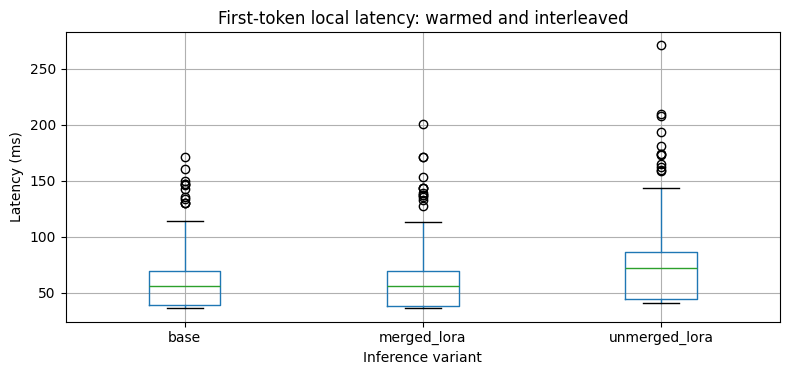

Accuracy: base 70.0% -> LoRA-trained 83.0%
All outputs saved to: /content/grpo_stage3_results


In [12]:
fig, ax = plt.subplots(figsize=(8,4))
measurements.boxplot(column='ttft_ms',by='model',ax=ax,showfliers=True)
ax.set_title('First-token local latency: warmed and interleaved')
ax.set_xlabel('Inference variant'); ax.set_ylabel('Latency (ms)')
plt.suptitle(''); plt.tight_layout(); plt.savefig(OUTPUT_DIR/'ttft_boxplot.png',dpi=160);plt.show()

print(f'Accuracy: base {BASE_ACCURACY:.1%} -> LoRA-trained {AFTER_ACCURACY:.1%}')
print('All outputs saved to:',OUTPUT_DIR)


### Interpretation

- **Base ≈ merged, unmerged slower:** expected LoRA overhead is visible; training did not accelerate the transformer.
- **All three ≈ equal:** LoRA overhead is too small to resolve with this setup.
- **Merged consistently faster than base:** investigate dtype, attention kernels, thermal/clocks, model load differences, and statistical variance before attributing it to GRPO.
- **Large p95 outliers:** repeat on an idle dedicated GPU and inspect prompt-length effects and GPU clock state.

For rigorous production TTFT, benchmark an inference server's streaming responses under controlled concurrency, include network and queue time, and measure first token arrival separately from tokenization/prefill. This notebook intentionally isolates local single-request latency.
